3558 epochs in 10 objects
3245 clean data points
filtercode  oid             
zg          672109100001130     623
            673112200001229     681
            1714101100000139     23
            1715104200004161     20
zi          672309100010027     197
            673312200002491     186
zr          672209100002601     721
            673212200021595     739
            1714201100000357     26
            1715204200000444     29
dtype: int64


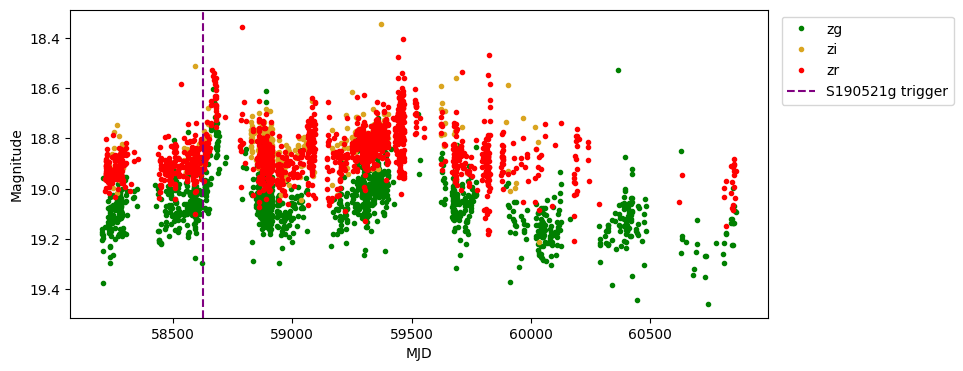

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt


#URL = "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"
#params = {"POS": "CIRCLE 192.42625 34.82472 0.000278",
#          "FORMAT": "csv"}

#r = requests.get(URL, params=params, timeout=180)
#r.raise_for_status()
#with open("S190521g.csv", "w") as f:
#    f.write(r.text)

lc = pd.read_csv("S190521g.csv")
print(len(lc), "epochs in", lc["oid"].nunique(), "objects")

# keep epochs with no quality flags set
lc = lc[lc["catflags"] == 0]
print(len(lc), "clean data points")

# sort in time and check coverage
lc = lc.sort_values("mjd")
print(lc.groupby(["filtercode", "oid"]).size())

colors = {"zg": "green", "zr": "red", "zi": "goldenrod"}
trigger = 58624.127   # S190521g, 2019-05-21 03:02 UTC

fig, ax = plt.subplots(figsize=(9, 4))
for band, d in lc.groupby("filtercode"):
    ax.plot(d["mjd"], d["mag"], "o", ms=3,
            color=colors[band], label=band)
ax.axvline(trigger, ls="--", color="purple",
           label="S190521g trigger")
ax.invert_yaxis()   # brighter is up
ax.set_xlabel("MJD"); ax.set_ylabel("Magnitude")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig("ztf_lightcurve.png", dpi=150)